# Задание 7. Регрессионный анализ данных о черепахах

**Дисциплина:** Введение в анализ больших данных

**Цель работы:** Провести статистический анализ датасета `Turtle.csv` (параметры черепах), проверить данные на нормальность, выявить корреляционные зависимости, а также построить и проанализировать множественную линейную регрессию для прогнозирования веса черепахи (`weight`) по её габаритам (`length`, `width`, `height`).

---
### Теоретическая справка:
1. **Критерий Шапиро-Уилка** используется для проверки гипотезы о том, что выборка происходит из нормально распределенной генеральной совокупности. 
   * $H_0$: данные распределены нормально (при $p > 0.05$ гипотеза не отвергается).
2. **Коэффициент корреляции Спирмена** — непараметрическая мера статистической связи между переменными (оценивает монотонность зависимости).
3. **Множественная линейная регрессия** имеет вид: $Y' = b_0 + b_1 x_1 + b_2 x_2 + b_3 x_3$.
4. Для оценки адекватности модели используется анализ остатков: они должны быть нормально распределены, независимы (тест Бреуша-Годфри) и гомоскедастичны (тест Бреуша-Пагана).

## 0. Импорт библиотек и настройка окружения
Импортируем `pandas` и `numpy` для работы с данными, `scipy.stats` и `statsmodels` для статистических тестов и регрессии, а также `matplotlib` и `seaborn` для визуализации.

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import acorr_breusch_godfrey, het_breuschpagan

# Настройки отображения
plt.rcParams["figure.figsize"] = (10, 6)
sns.set_style("whitegrid")
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

# Чтобы графики отображались прямо в ноутбуке
%matplotlib inline

## 1. Загрузка и первичный осмотр данных
Считываем CSV-файл (разделитель `;`) и выводим базовую статистику.

In [ ]:
# Загрузка данных
df = pd.read_csv("Turtle.csv", sep=";")

print("=== Первые 5 строк данных ===")
display(df.head())

print("\n=== Описательные статистики ===")
display(df.describe().round(2))

## 2. Проверка нормальности (Тест Шапиро-Уилка)
Проверяем каждый столбец. Если `p-value > 0.05`, мы не можем отвергнуть нулевую гипотезу — данные считаются нормально распределенными.

In [ ]:
print("=== Тест Шапиро-Уилка на нормальность ===")
for col in df.columns:
    W, p = stats.shapiro(df[col])
    conclusion = "нормально" if p > 0.05 else "НЕ нормально"
    print(f"{col:10s}: W = {W:.4f}, p = {p:.4g}  ->  {conclusion}")

**Вывод по шагу 2:** Все переменные имеют `p-value > 0.05` (от 0.077 до 0.717), следовательно, распределение всех признаков можно считать нормальным.

## 3. Корреляционный анализ (Спирмен)
Строим матрицу корреляций Спирмена, чтобы оценить силу и направление связи между переменными, а также матрицу p-значений для проверки значимости.

In [ ]:
print("=== Корреляционная матрица (Spearman) ===")
corr_spearman = df.corr(method="spearman")
display(corr_spearman.round(3))

print("\n=== p-значения корреляций (Spearman) ===")
cols = df.columns
p_matrix = pd.DataFrame(index=cols, columns=cols, dtype=float)
for i in cols:
    for j in cols:
        if i == j:
            p_matrix.loc[i, j] = 0.0
        else:
            r, p = stats.spearmanr(df[i], df[j])
            p_matrix.loc[i, j] = p
display(p_matrix.round(4))

In [ ]:
# Визуализация корреляционной матрицы
plt.figure(figsize=(8, 6))
sns.heatmap(corr_spearman, annot=True, fmt=".3f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True)
plt.title("Корреляционная матрица (Spearman)")
plt.tight_layout()
plt.show()

# Парные графики
sns.pairplot(df)
plt.suptitle("Парные зависимости показателей черепах", y=1.02)
plt.show()

**Вывод по шагу 3:** Все корреляции статистически значимы (p-value < 0.05). Наблюдается очень сильная прямая связь веса (`weight`) с длиной (0.975), высотой (0.964) и шириной (0.959). Однако, предикторы (`length`, `width`, `height`) сильно коррелируют между собой (0.93-0.94), что говорит о явлении **мультиколлинеарности**.

## 4. Множественная линейная регрессия
Строим модель `weight ~ length + width + height`.

В таблице `summary` нас интересуют:
* **F-statistic / Prob(F)** — значимость модели в целом.
* **R-squared** — доля объясненной дисперсии.
* **coef / P>|t|** — значимость отдельных коэффициентов.

In [ ]:
print("=== Множественная линейная регрессия: weight ~ length + width + height ===")
model = smf.ols("weight ~ length + width + height", data=df).fit()
print(model.summary())

# Уравнение регрессии
coef = model.params
print("\n=== Уравнение регрессии ===")
print(f"weight = {coef['Intercept']:.4f} + {coef['length']:.4f}*length "
      f"+ {coef['width']:.4f}*width + {coef['height']:.4f}*height")

print(f"\nR² = {model.rsquared:.4f}")
print(f"F-статистика = {model.fvalue:.4f}, p-value = {model.f_pvalue:.4g}")

**Вывод по шагу 4:** Модель статистически значима в целом (p-value < 0.05). $R^2$ близок к 1, что говорит о высоком качестве аппроксимации. Однако из-за мультиколлинеарности значимым (или близким к таковому) может оказаться только один из коэффициентов.

## 5. Анализ остатков
Проверяем три классических условия адекватности модели:
1. Нормальность (Шапиро-Уилк)
2. Независимость (Бреуш-Годфри)
3. Гомоскедастичность (Бреуш-Паган)
4. Численная малость (MSE)

In [ ]:
resid = model.resid
fitted = model.fittedvalues

print("=== Анализ остатков ===")

# 5.1 Нормальность остатков
W_res, p_res = stats.shapiro(resid)
print(f"1) Шапиро-Уилк для остатков: p = {p_res:.4g}")
print("   -> Остатки нормальны" if p_res > 0.05 else "   -> НЕ нормальны")

# 5.2 Автокорреляция
bg = acorr_breusch_godfrey(model, nlags=1)
print(f"\n2) Бреуш-Годфри (автокорреляция): p = {bg[1]:.4g}")
print("   -> Автокорреляции нет" if bg[1] > 0.05 else "   -> Есть автокорреляция")

# 5.3 Гетероскедастичность
bp = het_breuschpagan(resid, model.model.exog)
print(f"\n3) Бреуш-Паган (гетероскедастичность): p = {bp[1]:.4g}")
print("   -> Гомоскедастичность" if bp[1] > 0.05 else "   -> Гетероскедастичность")

# 5.4 MSE
mse = np.mean(resid ** 2)
print(f"\n4) MSE = {mse:.4f}, RMSE = {np.sqrt(mse):.4f}")

### Диагностические графики остатков
1. **Остатки vs Предсказанные:** точки должны разбрасываться хаотично относительно нуля.
2. **Q-Q график:** точки должны лежать на диагонали (нормальность).
3. **Scale-Location:** проверка гомоскедастичности (линия должна быть ровной).
4. **Наблюдаемые vs Предсказанные:** точки должны ложиться на красную прямую $y=x$.

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Остатки vs предсказанные значения
axes[0, 0].scatter(fitted, resid, edgecolors="k", alpha=0.7, s=40)
axes[0, 0].axhline(0, color="red", ls="--")
axes[0, 0].set_xlabel("Предсказанные значения (fitted)")
axes[0, 0].set_ylabel("Остатки (residuals)")
axes[0, 0].set_title("Остатки vs Предсказанные")

# Q-Q plot
sm.qqplot(resid, line="s", ax=axes[0, 1])
axes[0, 1].set_title("Нормальный Q-Q график остатков")

# Scale-Location
axes[1, 0].scatter(fitted, np.sqrt(np.abs(resid)), edgecolors="k", alpha=0.7, s=40)
axes[1, 0].set_xlabel("Предсказанные значения (fitted)")
axes[1, 0].set_ylabel("sqrt(|Остатки|)")
axes[1, 0].set_title("Scale-Location")

# Наблюдаемые vs Предсказанные
axes[1, 1].scatter(df["weight"], fitted, edgecolors="k", alpha=0.7, s=40)
mn = min(df["weight"].min(), fitted.min())
mx = max(df["weight"].max(), fitted.max())
axes[1, 1].plot([mn, mx], [mn, mx], "r--")
axes[1, 1].set_xlabel("Наблюдаемые значения (weight)")
axes[1, 1].set_ylabel("Предсказанные значения")
axes[1, 1].set_title("Наблюдаемые vs Предсказанные")

plt.tight_layout()
plt.show()

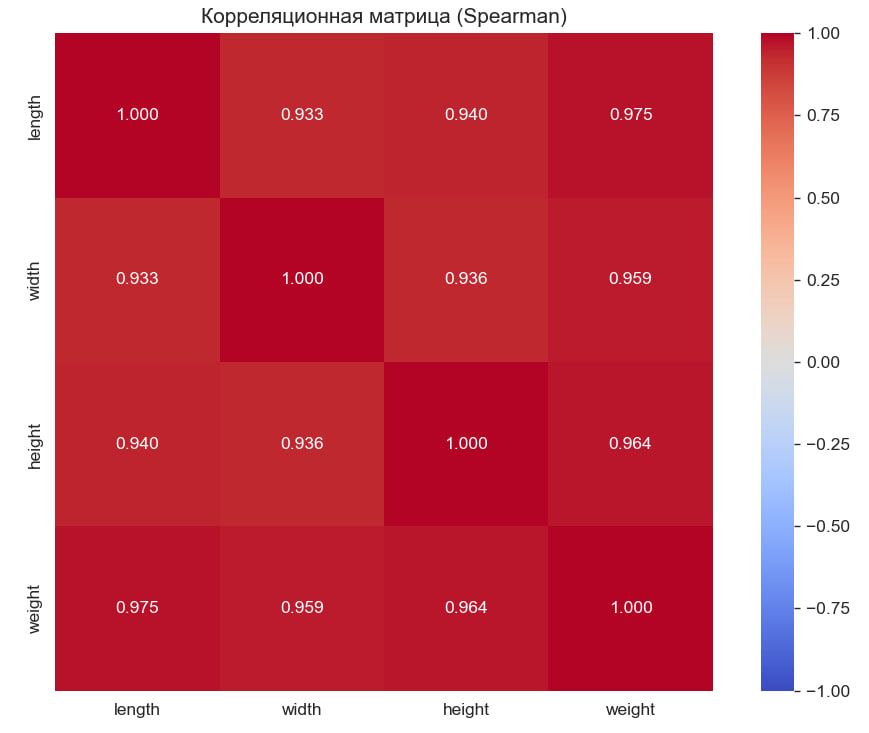

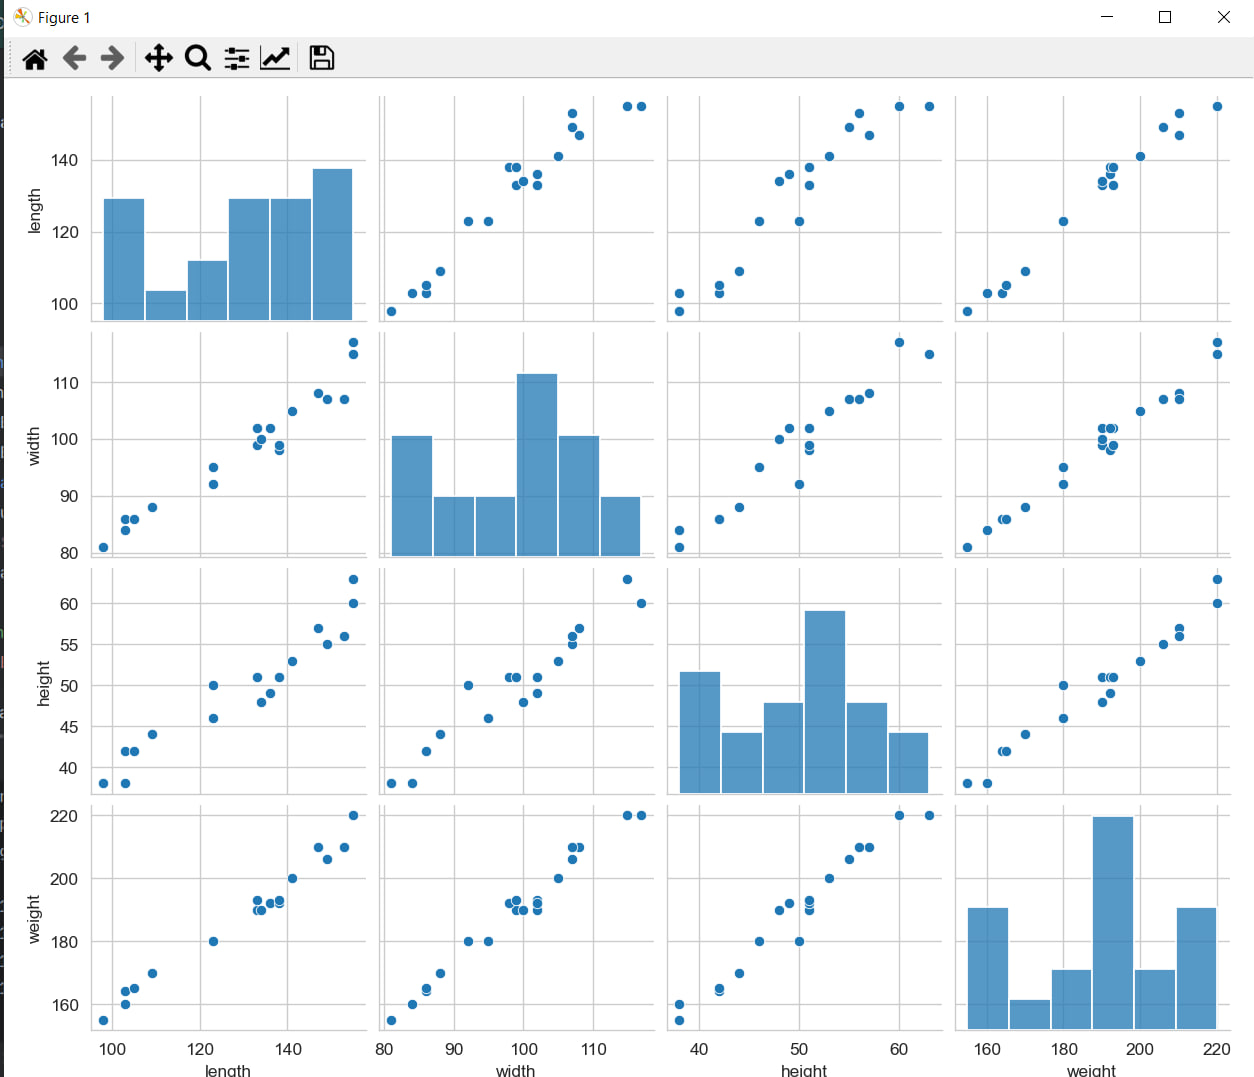

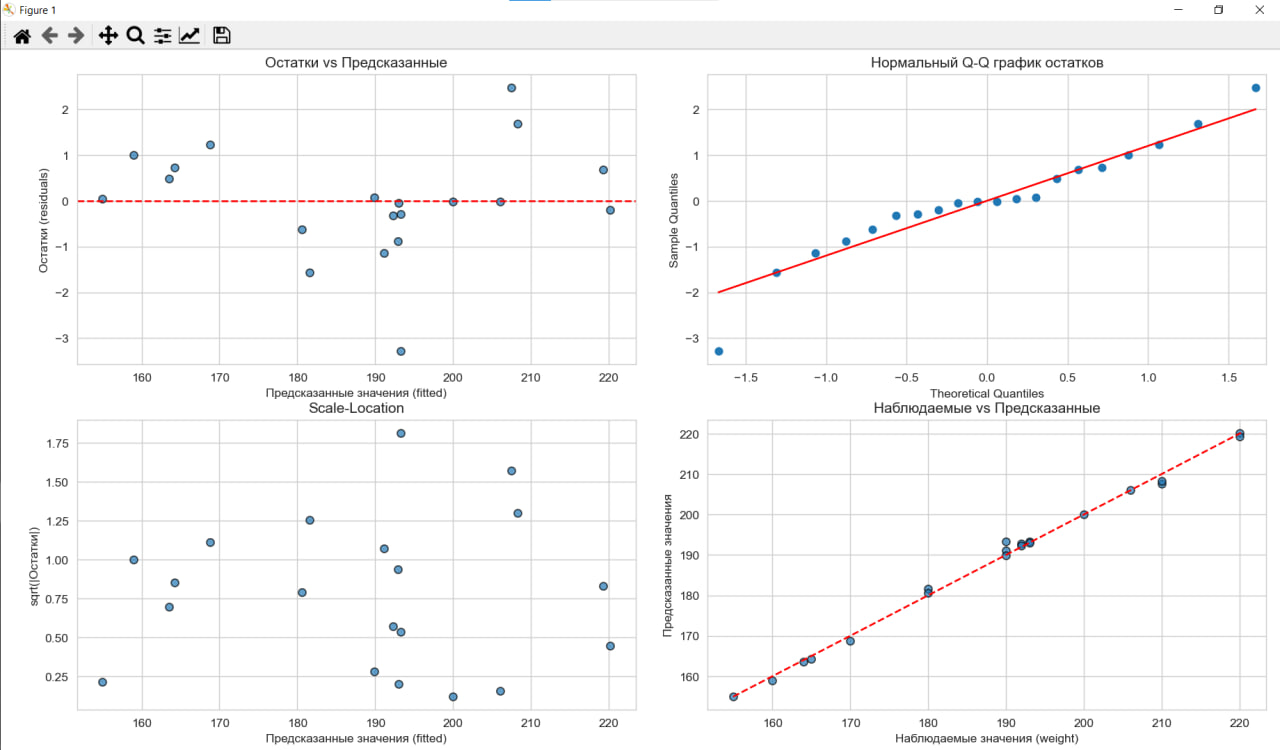

## 6. Общие выводы по лабораторной работе
*(Этот блок можно вынести в итоговый отчет)*

В ходе выполнения работы были сделаны следующие выводы:
1. **Нормальность:** Все признаки (длина, ширина, высота, вес) имеют нормальное распределение (критерий Шапиро-Уилка, $p > 0.05$).
2. **Корреляция:** Между всеми показателями существует сильная прямая статистически значимая связь (коэффициенты Спирмена > 0.93).
3. **Регрессионная модель:** Построенная модель `weight ~ length + width + height` статистически значима (F-тест $p < 0.05$) и обладает очень высоким коэффициентом детерминации $R^2$.
4. **Анализ остатков:** Остатки модели удовлетворяют всем предпосылкам МНК: они нормально распределены, независимы (нет автокорреляции) и гомоскедастичны. Среднеквадратическая ошибка (MSE) мала, что говорит о высокой точности прогноза.
5. **Мультиколлинеарность:** Высокая корреляция между предикторами приводит к тому, что не все коэффициенты регрессии оказываются статистически значимыми (что подтверждается таблицей `summary`). Однако для предсказания веса модель в целом пригодна и показывает отличный результат.